**Resultados de la aplicación de POSIT**:
Aplicamos el algoritmo POSIT para puntos coplanares, utilizando las correspondencias entre los cinco puntos 3D de la H y sus posiciones 2D en la fotografía, junto con la matriz intrínseca (K) de la cámara,que tenemos como dato.
Con este algoritmo pudimos estimar la pose de la cámara respecto del sistema de coordenadas de la H, y obtuvimos la matriz de rotación (R) y el vector de traslación (t).
Para evaluar la pose estimada, proyectamos nuevamente, utilizando R,t,K, los puntos 3D sobre el plano imagen y calculamos el RMSE respecto de las coordenadas 2D observadas.

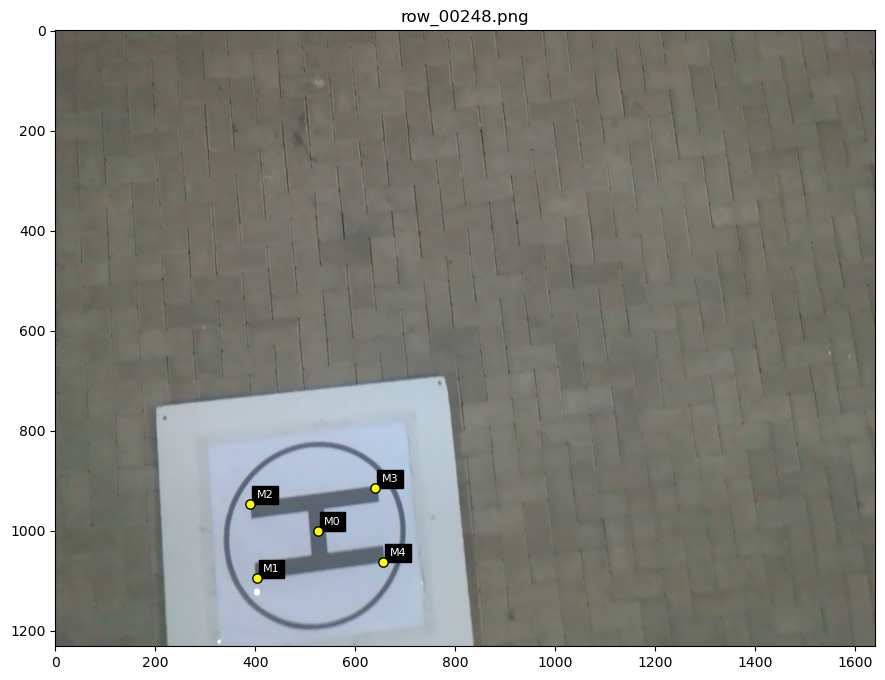

In [ ]:
matriz_K = pd.read_csv(os.path.join(DIR_HELI, 'K.csv'), sep=';', header=None).to_numpy()
puntos_3d = pd.read_csv(os.path.join(DIR_HELI, 'object_points.csv'), sep=';', header=0, index_col=0).to_numpy(dtype=float)

#ejercicio 6.a:
# Aplicamos la versión de POSIT para puntos coplanares,ya que los cinco puntos dados pertenecen al plano UV (W = 0).

img_heli = leer_imagen(os.path.join(DIR_HELI, 'row_00248.png'))

# Puntos 2D marcados en la imagen
puntos_2d = np.array([
    [525, 1000],  #Centro M0
    [403, 1095],  #Superior izquierdo
    [390, 947],   #Superior derecho
    [640, 915],   #Inferior derecho
    [656, 1063]   #Inferior izquierdo
])
etiquetas_heli = ['M0', 'M1', 'M2', 'M3', 'M4']

mostrar_puntos(img_heli, puntos_2d, etiquetas_heli, titulo='row_00248.png')

In [ ]:
#estimamos R y t
MaxIt=100
atol=1e-8
R,t=alc.aplicarPOSIT(puntos_3d, puntos_2d, matriz_K, MaxIt, atol)
print("Matriz de rotación (R): ", R)
print("Chequeamos que es R es efectivamente una matriz de rotación, es decir que det(R) ≈ 1 y RᵀR ≈ I")
print("Determinante(R):", alc.determinante_3x3(R))
print("¿Es aproximadamente 1?")
print(alc.error(alc.determinante_3x3(R),1)<atol)
producto = alc.multiplicar(alc.traspuesta(R), R)
print("R traspuesta por R:")
print(producto)
print("¿Es aproximadamente la identidad?")
print(alc.matricesIguales(producto,np.eye(3)))
print("Vector de traslación (t):", t)
print("Chequeamos que la pose sea válida, y el error de reproyección(RMSE)")
validos, error = alc.evaluarPose(R, t, puntos_3d, puntos_2d, matriz_K)
print("Puntos válidos:", validos)
print("RMSE:", error)

Matriz de rotación (R):  [[-0.1333 -0.9608  0.2431]
 [-0.9672  0.0725 -0.2435]
 [ 0.2163 -0.2676 -0.9389]]
Chequeamos que es R es efectivamente una matriz de rotación, es decir que det(R) ≈ 1 y RᵀR ≈ I
Determinante(R): 1.0
¿Es aproximadamente 1?
True
R traspuesta por R:
[[ 1.0000e+00  2.0817e-17 -5.5511e-17]
 [ 2.0817e-17  1.0000e+00  0.0000e+00]
 [-5.5511e-17  0.0000e+00  1.0000e+00]]
¿Es aproximadamente la identidad?
True
Vector de traslación (t): [-0.7046  0.9199  4.5288]
Chequeamos que la pose sea válida, y el error de reproyección(RMSE)
Puntos válidos: 5
RMSE: 2.2393522989195027


A continuación, podemos observar en un gráfico, la pequeña diferencia entre las posiciones 2D originales de los puntos y las obtenidas al proyectarlos utilizando la pose estimada por POSIT.

In [ ]:
#proyectamos los puntos 3D utilizando la pose estimada por POSIT
puntos_proyectados = alc.proyectarPuntosUVW(puntos_3d, matriz_K, R, t)

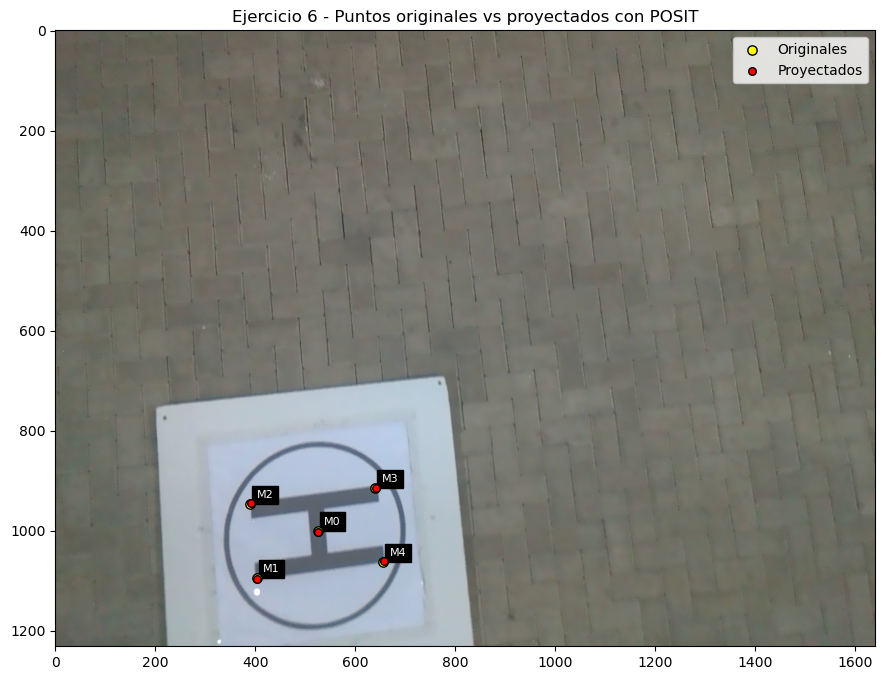

In [ ]:
mostrar_puntos(img_heli, puntos_2d, etiquetas_heli, puntos_proyectados,
               'Ejercicio 6 - Puntos originales vs proyectados con POSIT')

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

Para que la cámara observe la letra H de manera vertical, debemos determinar una nueva matriz de rotación $R$.
Como los puntos de la H pertenecen al plano $UV$, dado que todos tienen $W=0$, el eje óptico de la cámara debe ser perpendicular a dicho plano.
Además, tenemos que considerar el punto blanco, que señala la esquina superior izquierda de la H y nos ayuda a determinar cómo debe quedar orientada la imagen.
La matriz de rotación se construye a partir de los vectores unitarios y mutuamente ortogonales $i$, $j$ y $k$, que forman una base ortonormal (BON):

$$
R=\begin{pmatrix}
i^T\\
j^T\\
k^T
\end{pmatrix},
\qquad k=i\times j
$$

Para determinar la matriz de rotación, vamos a considerar las coordenadas 3D de los puntos de H, en particular tendremos
en cuenta los puntos: 

$M_0=(0,0,0)$ (centro de la H) y $M_1=(-0.175,0.3,0)$ (punto más cercano al punto blanco en la esquina superior izquierda de la H)

En la foto original, $M_1$ aparece a la izquierda y debajo de $M_0$, ya que sus coordenadas 2D son:

$$
m_0=(525,1000),\qquad m_1=(403,1095)
$$


Para la nueva pose queremos que $M_1$ aparezca arriba a la izquierda de $M_0$.
Partiendo de la siguiente ecuación:

$$
\begin{pmatrix}
X\\
Y\\
Z
\end{pmatrix}
=
R
\begin{pmatrix}
U\\
V\\
W
\end{pmatrix}
+t
$$

Como las coordenadas de la imagen aumentan hacia la derecha y hacia abajo, buscamos que $M_1$ tenga $X_1<0$ e $Y_1<0$ en el sistema de la nueva cámara, tomando como referencia el centro $M_0$.

Entonces, si tomamos

$$
i=(1,0,0)
$$

para que la dirección horizontal positiva de $U$ se proyecte hacia la derecha, y así logramos que $M_1$, que tiene $U_1<0$, aparezca a la izquierda.

También elegimos:

$$
j=(0,-1,0)
$$

porque queremos que $M_1$, cuya coordenada $V_1=0.3$ es positiva, aparezca por encima de $M_0$ en la imagen. Como la coordenada vertical de la imagen aumenta hacia abajo, necesitamos que su coordenada $Y_1$ respecto de la cámara sea negativa.

Como queremos que $M_0$ quede sobre el eje óptico, tomamos $t_x=t_y=0$. Entonces:

$$
X=U,\qquad Y=-V
$$

Finalmente, calculamos:

$$
k=i\times j=(0,0,-1)
$$

Este vector es perpendicular al plano $UV$ y apunta hacia abajo, suponiendo que el eje $W$ positivo apunta hacia arriba.

Por lo tanto, la matriz de rotación que nos sirve es:

$$
R=
\begin{pmatrix}
1&0&0\\
0&-1&0\\
0&0&-1
\end{pmatrix}
$$

Y esta matriz cumple las condiciones de una matriz de rotación:

$$
R^TR=I,\qquad \det(R)=1
$$

Respecto al vector de traslación t, si buscamos ubicar el dron exactamente sobre el centro de la H, queremos que $M_0$ quede sobre el eje óptico de la cámara, a una profundidad $h>0$ , que representaría la altura a la que se encunetra el dron.

Utilizamos la ecuación:

$$
RM_0+t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix}
$$

Como $M_0=(0,0,0)$, obtenemos:

$$
t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix}
$$


Finalmente, la pose de la cámara que cumple las condiciones está dada por:

$$
\boxed{
R=
\begin{pmatrix}
1&0&0\\
0&-1&0\\
0&0&-1
\end{pmatrix},
\qquad
t=
\begin{pmatrix}
0\\
0\\
h
\end{pmatrix},
\quad h>0
}
$$

